In [1]:
import pandas as pd
from IPython.display import display
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

In [2]:
# Colors used across the charts
BLUE = "#2a78d6"
ORANGE = "#eb6834"
AQUA = "#1baf7a"
INK = "#0b0b0b"
TEXT_GRAY = "#52514e"
GRID = "#e4e3df"

# Apply the same style to all charts
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": GRID,
    "axes.labelcolor": TEXT_GRAY,
    "axes.titlecolor": INK,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": GRID,
    "grid.linewidth": 0.8,
    "xtick.color": TEXT_GRAY,
    "ytick.color": TEXT_GRAY,
    "font.size": 10,
    "legend.frameon": False
})

In [3]:
# Read the cleaned startup funding file and investor file
df = pd.read_csv("startup_funding_clean.csv", parse_dates=["funding_date"])
investors = pd.read_csv("investors_long.csv")

# Keep rows where the funding amount was disclosed
disclosed = df[df["amount_disclosed"] == 1].copy()

# Check the first few rows
display(df.head())

,deal_id,sr_no,funding_date,year,quarter,month,month_name,year_month,startup_name,industry_vertical,...,is_multi_city,investors_name,investor_count,investment_type,funding_stage,amount_usd,amount_usd_mn,amount_disclosed,deal_size_bucket,remarks
0,1,2990,2015-01-02,2015.0,Q1,1.0,Jan,2015-01,Lenskart,NaN,...,0,"TPG Growth, TR Capital, IDG Ventures",3,Private Equity,Private Equity,2150000.0,2.150,1,$1M-5M,NaN
1,2,2991,2015-01-02,2015.0,Q1,1.0,Jan,2015-01,VioletStreet,NaN,...,0,"Venkat Vallabhneni, Sudhakar Reddy, Srinivasa ...",3,Seed Funding,Seed / Angel,315000.0,0.315,1,< $1M,NaN
2,3,2992,2015-01-05,2015.0,Q1,1.0,Jan,2015-01,Lookup,NaN,...,0,"DeNA Co., Japan & Teruhide Sato (in Addition t...",4,Seed Funding,Seed / Angel,380000.0,0.380,1,< $1M,NaN
3,4,2993,2015-01-05,2015.0,Q1,1.0,Jan,2015-01,#Fame,NaN,...,0,TO THE NEW Ventures,1,Private Equity,Private Equity,10000000.0,10.000,1,$5M-20M,NaN
4,5,2994,2015-01-05,2015.0,Q1,1.0,Jan,2015-01,Gympik,NaN,...,0,"Tom Clausen, Rohan Ajila, Haldyn Glass",3,Seed Funding,Seed / Angel,135000.0,0.135,1,< $1M,NaN


In [4]:
print("DATASET OVERVIEW")
print("----------------")
print("Total funding deals:", f"{len(df):,}")
print("Unique startups:", f"{df['startup_name'].nunique():,}")
print("Unique named investors:", f"{investors['investor_name'].nunique():,}")
print("First funding date:", df["funding_date"].min().strftime("%d %b %Y"))
print("Last funding date:", df["funding_date"].max().strftime("%d %b %Y"))
print("Deals with disclosed amounts:", f"{len(disclosed):,}")
print("Disclosure rate:", f"{len(disclosed) / len(df):.1%}")
print("Total disclosed funding (USD billion):", f"${disclosed['amount_usd'].sum() / 1e9:,.2f} bn")
print("Average disclosed deal (USD million):", f"${disclosed['amount_usd'].mean() / 1e6:,.2f} mn")
print("Median disclosed deal (USD million):", f"${disclosed['amount_usd'].median() / 1e6:,.2f} mn")
print("Deal amount skewness:", round(disclosed["amount_usd"].skew(), 2))

DATASET OVERVIEW
----------------
Total funding deals: 3,043
Unique startups: 2,276
Unique named investors: 3,107
First funding date: 02 Jan 2015
Last funding date: 13 Jan 2020
Deals with disclosed amounts: 2,072
Disclosure rate: 68.1%
Total disclosed funding (USD billion): $34.30 bn
Average disclosed deal (USD million): $16.55 mn
Median disclosed deal (USD million): $1.77 mn
Deal amount skewness: 17.61


### Q1 — Funding trends by year

In [5]:
# Count deals and calculate total and median disclosed funding by year
yearly = df.groupby("year").agg(
    deals=("deal_id", "count"),
    total_funding_usd=("amount_usd", "sum"),
    median_deal_usd=("amount_usd", "median"),
    disclosed_rate=("amount_disclosed", "mean")
)

# Convert funding amounts to easier units
yearly["funding_bn"] = yearly["total_funding_usd"] / 1e9
yearly["median_mn"] = yearly["median_deal_usd"] / 1e6
yearly["disclosed_pct"] = yearly["disclosed_rate"] * 100

display(yearly[["deals", "funding_bn", "median_mn", "disclosed_pct"]].round(2))

,deals,funding_bn,median_mn,disclosed_pct
year,,,,
2015.0,935,8.67,1.50,69.84
2016.0,993,3.83,1.00,59.01
2017.0,687,10.43,2.25,66.38
2018.0,310,5.12,4.00,85.48
2019.0,111,5.85,12.00,94.59
2020.0,7,0.39,9.00,100.00


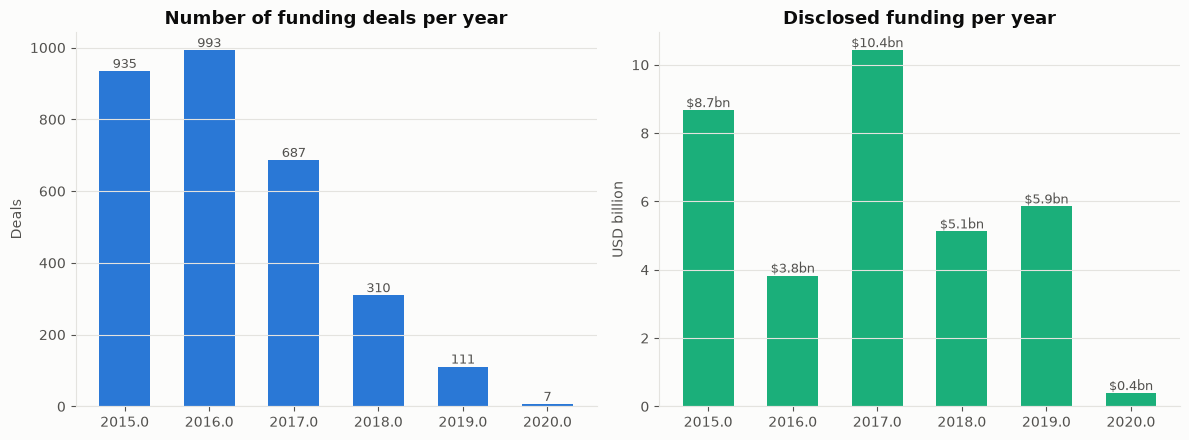

In [6]:
# Compare deal counts and total disclosed funding by year
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].bar(yearly.index.astype(str), yearly["deals"], color=BLUE, width=0.6)
axes[0].set_title("Number of funding deals per year")
axes[0].set_ylabel("Deals")
axes[0].grid(axis="x", visible=False)

for position, value in enumerate(yearly["deals"]):
    axes[0].text(position, value, f"{value:,.0f}", ha="center", va="bottom", fontsize=9, color=TEXT_GRAY)

axes[1].bar(yearly.index.astype(str), yearly["funding_bn"], color=AQUA, width=0.6)
axes[1].set_title("Disclosed funding per year")
axes[1].set_ylabel("USD billion")
axes[1].grid(axis="x", visible=False)

for position, value in enumerate(yearly["funding_bn"]):
    axes[1].text(position, value, f"${value:,.1f}bn", ha="center", va="bottom", fontsize=9, color=TEXT_GRAY)

plt.tight_layout()
plt.show()

### Monthly funding deal trend

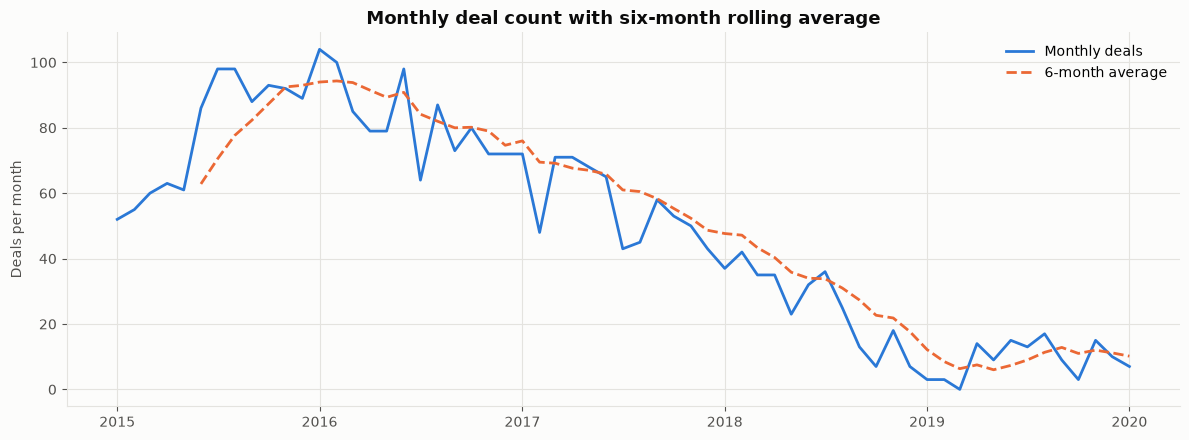

In [7]:
# Count deals by month and calculate a six-month moving average
monthly_deals = df.set_index("funding_date").resample("MS")["deal_id"].count()
monthly_average = monthly_deals.rolling(window=6).mean()

plt.figure(figsize=(12, 4.5))
plt.plot(monthly_deals.index, monthly_deals.values, color=BLUE, linewidth=2, label="Monthly deals")
plt.plot(monthly_average.index, monthly_average.values, color=ORANGE, linewidth=2, linestyle="--", label="6-month average")
plt.title("Monthly deal count with six-month rolling average")
plt.ylabel("Deals per month")
plt.legend()
plt.tight_layout()
plt.show()

### Sector analysis

In [8]:
# Exclude rows where the sector is unknown
known_sector = df[df["sector"] != "Unknown"].copy()
known_disclosed_sector = disclosed[disclosed["sector"] != "Unknown"].copy()

# Find the top 10 sectors by deal count and disclosed funding
sector_deals = known_sector["sector"].value_counts().head(10)
sector_funding = (
    known_disclosed_sector.groupby("sector")["amount_usd"]
    .sum()
    .div(1e6)
    .nlargest(10)
)

print("Top sectors by number of deals")
display(sector_deals.to_frame("deals"))
print("Top sectors by disclosed funding (USD million)")
display(sector_funding.to_frame("funding_usd_million").round(1))

Top sectors by number of deals


,deals
sector,
Consumer Internet,942
"Technology, SaaS & IT",666
E-commerce & Retail,438
HealthTech & Wellness,143
FinTech & Financial Services,131
Logistics & Mobility,128
Food & Beverage,119
Others,113
EdTech,90


Top sectors by disclosed funding (USD million)


,funding_usd_million
sector,
E-commerce & Retail,11597.0
Consumer Internet,6254.1
"Technology, SaaS & IT",4342.0
FinTech & Financial Services,3819.6
Logistics & Mobility,2327.2
HealthTech & Wellness,1472.4
Food & Beverage,993.7
Others,819.6
EdTech,795.3


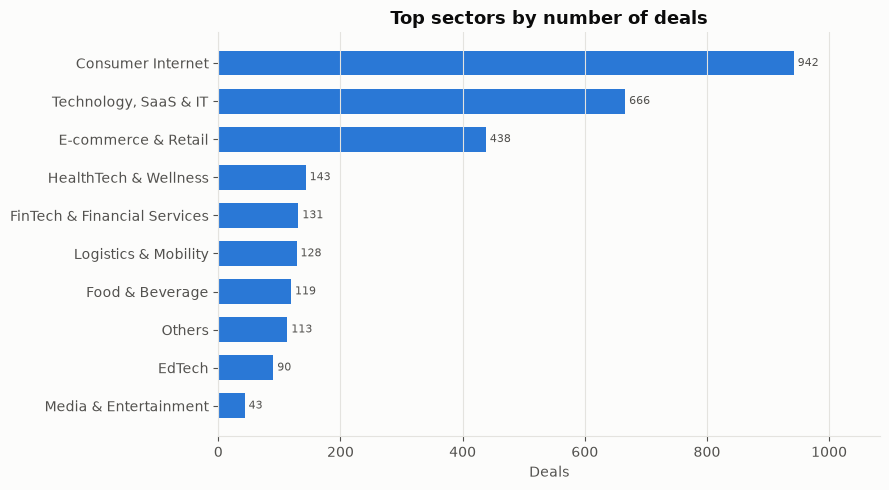

In [9]:
# Visualize the top 10 sectors by deal count
sector_deals_sorted = sector_deals.sort_values()

plt.figure(figsize=(9, 5))
plt.barh(sector_deals_sorted.index, sector_deals_sorted.values, color=BLUE, height=0.65)
plt.title("Top sectors by number of deals")
plt.xlabel("Deals")
plt.grid(axis="y", visible=False)

for position, value in enumerate(sector_deals_sorted.values):
    plt.text(value, position, f" {value:,.0f}", va="center", fontsize=8, color=TEXT_GRAY)

plt.margins(x=0.15)
plt.tight_layout()
plt.show()

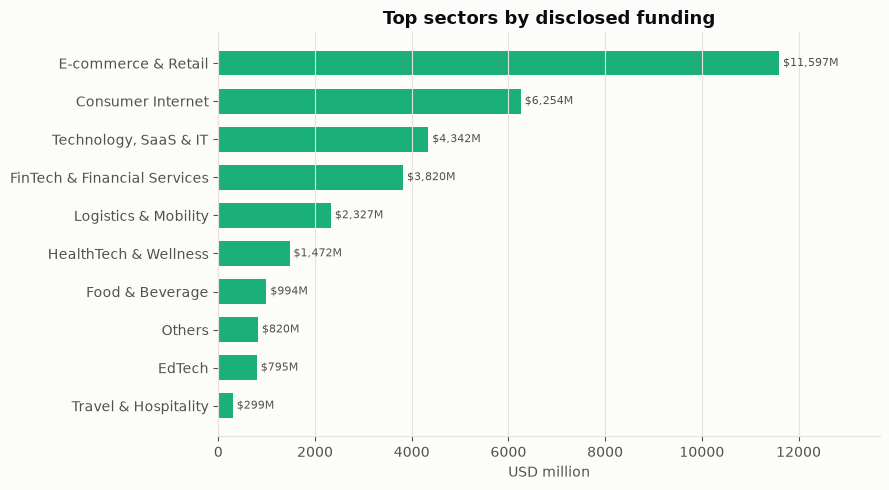

In [10]:
# Visualize the top 10 sectors by disclosed funding
sector_funding_sorted = sector_funding.sort_values()

plt.figure(figsize=(9, 5))
plt.barh(sector_funding_sorted.index, sector_funding_sorted.values, color=AQUA, height=0.65)
plt.title("Top sectors by disclosed funding")
plt.xlabel("USD million")
plt.grid(axis="y", visible=False)

for position, value in enumerate(sector_funding_sorted.values):
    plt.text(value, position, f" ${value:,.0f}M", va="center", fontsize=8, color=TEXT_GRAY)

plt.margins(x=0.18)
plt.tight_layout()
plt.show()

### City analysis

In [11]:
# Exclude rows where city is unknown
known_city = df[df["city"] != "Unknown"].copy()
known_disclosed_city = disclosed[disclosed["city"] != "Unknown"].copy()

# Top cities by deal count and disclosed funding
city_deals = known_city["city"].value_counts().head(10)
city_funding = (
    known_disclosed_city.groupby("city")["amount_usd"]
    .sum()
    .div(1e6)
    .nlargest(10)
)

top_three_city_share = city_deals.head(3).sum() / len(known_city)

print("Top cities by number of deals")
display(city_deals.to_frame("deals"))
print("Top cities by disclosed funding (USD million)")
display(city_funding.to_frame("funding_usd_million").round(1))
print("Share of known-city deals from the top three cities:", f"{top_three_city_share:.1%}")

Top cities by number of deals


,deals
city,
Bengaluru,853
Mumbai,575
New Delhi,464
Gurugram,343
Pune,112
Hyderabad,100
Chennai,99
Noida,94
Ahmedabad,41


Top cities by disclosed funding (USD million)


,funding_usd_million
city,
Bengaluru,14972.5
Mumbai,4964.6
Gurugram,3893.6
New Delhi,3370.9
Noida,1283.2
Chennai,756.8
Pune,717.6
Menlo Park,450.0
Hyderabad,401.7


Share of known-city deals from the top three cities: 66.2%


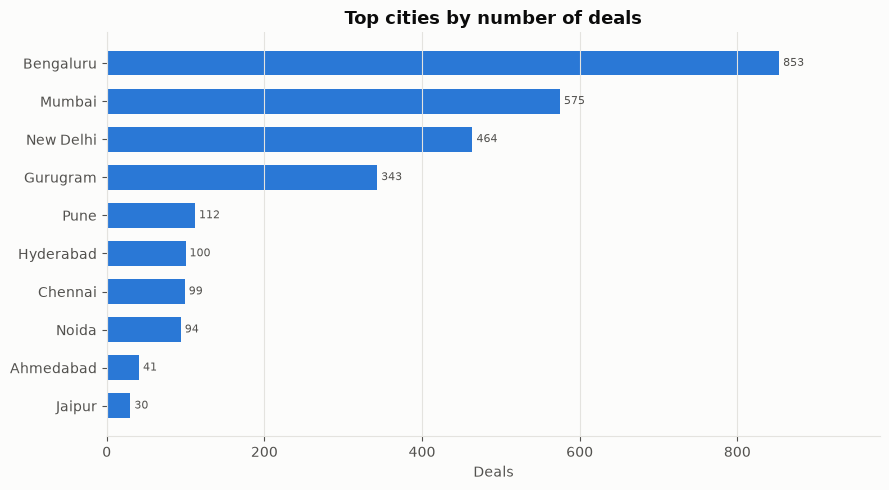

In [12]:
# Plot the top cities by deal count
city_deals_sorted = city_deals.sort_values()

plt.figure(figsize=(9, 5))
plt.barh(city_deals_sorted.index, city_deals_sorted.values, color=BLUE, height=0.65)
plt.title("Top cities by number of deals")
plt.xlabel("Deals")
plt.grid(axis="y", visible=False)

for position, value in enumerate(city_deals_sorted.values):
    plt.text(value, position, f" {value:,.0f}", va="center", fontsize=8, color=TEXT_GRAY)

plt.margins(x=0.15)
plt.tight_layout()
plt.show()

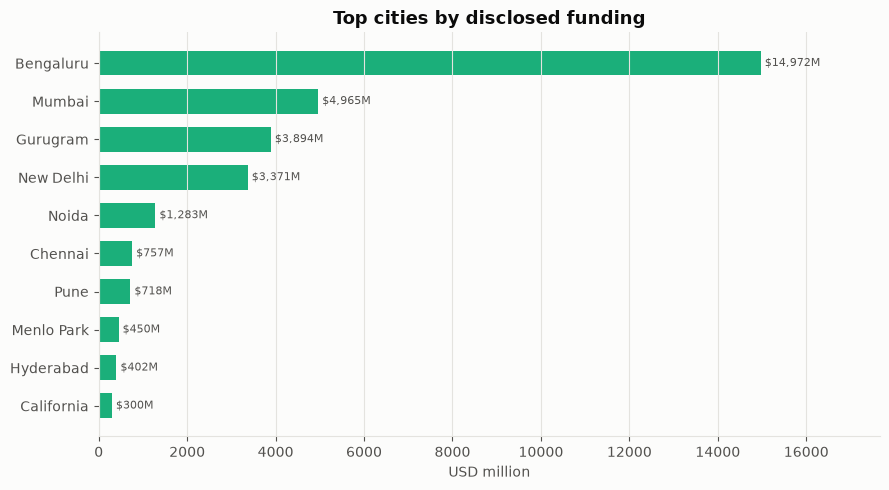

In [13]:
# Plot the top cities by disclosed funding
city_funding_sorted = city_funding.sort_values()

plt.figure(figsize=(9, 5))
plt.barh(city_funding_sorted.index, city_funding_sorted.values, color=AQUA, height=0.65)
plt.title("Top cities by disclosed funding")
plt.xlabel("USD million")
plt.grid(axis="y", visible=False)

for position, value in enumerate(city_funding_sorted.values):
    plt.text(value, position, f" ${value:,.0f}M", va="center", fontsize=8, color=TEXT_GRAY)

plt.margins(x=0.18)
plt.tight_layout()
plt.show()

### Deal size distribution

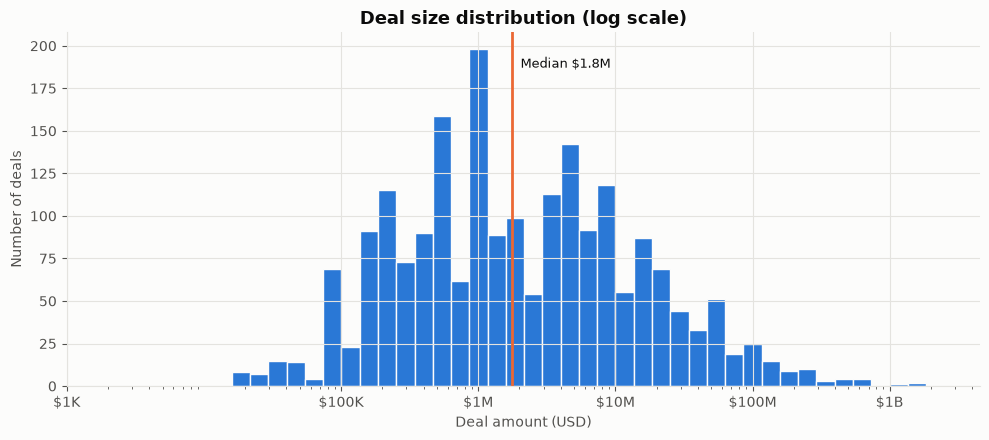

In [14]:
# Show the distribution of disclosed funding amounts.
# A logarithmic scale helps display both small and very large deals.
minimum_amount = disclosed["amount_usd"].min()
maximum_amount = disclosed["amount_usd"].max()
histogram_bins = np.logspace(np.log10(minimum_amount), np.log10(maximum_amount), 40)
median_amount = disclosed["amount_usd"].median()

plt.figure(figsize=(10, 4.5))
plt.hist(disclosed["amount_usd"], bins=histogram_bins, color=BLUE, edgecolor="#fcfcfb", linewidth=1)
plt.xscale("log")
plt.axvline(median_amount, color=ORANGE, linewidth=2)
plt.title("Deal size distribution (log scale)")
plt.xlabel("Deal amount (USD)")
plt.ylabel("Number of deals")

# Format the tick labels in thousands or millions without a custom function
tick_values = [1000, 100000, 1000000, 10000000, 100000000, 1000000000]
tick_labels = ["$1K", "$100K", "$1M", "$10M", "$100M", "$1B"]
plt.xticks(tick_values, tick_labels)
plt.text(median_amount * 1.15, plt.ylim()[1] * 0.9,
         f"Median ${median_amount / 1e6:.1f}M", color=INK, fontsize=9)
plt.tight_layout()
plt.show()

In [15]:
# Count deals in each deal-size category
bucket_order = ["< $1M", "$1M-5M", "$5M-20M", "$20M-100M", "$100M+", "Undisclosed"]
deal_size_counts = df["deal_size_bucket"].value_counts().reindex(bucket_order, fill_value=0)

display(deal_size_counts.to_frame("number_of_deals"))

,number_of_deals
deal_size_bucket,
< $1M,751
$1M-5M,605
$5M-20M,434
$20M-100M,210
$100M+,72
Undisclosed,971


### Funding stages

In [16]:
# Summarize deals and funding amounts by funding stage
funding_stage_summary = df.groupby("funding_stage").agg(
    deals=("deal_id", "count"),
    median_amount_usd=("amount_usd", "median"),
    total_amount_usd=("amount_usd", "sum")
)

# Convert to millions and remove unknown stage
funding_stage_summary["median_million"] = funding_stage_summary["median_amount_usd"] / 1e6
funding_stage_summary["total_million"] = funding_stage_summary["total_amount_usd"] / 1e6
funding_stage_summary = funding_stage_summary[funding_stage_summary.index != "Unknown"]
funding_stage_summary = funding_stage_summary.sort_values("deals", ascending=False)

display(funding_stage_summary[["deals", "median_million", "total_million"]].round(2))

,deals,median_million,total_million
funding_stage,,,
Seed / Angel,1541,0.37,1056.08
Private Equity,1363,6.00,27320.87
Series A,33,3.45,247.57
Debt,29,4.90,185.18
Series B,21,15.80,957.20
Series D+,20,55.00,1987.67
Other (Venture / Corporate / Bridge),18,14.68,1288.80
Series C,14,50.00,1044.72


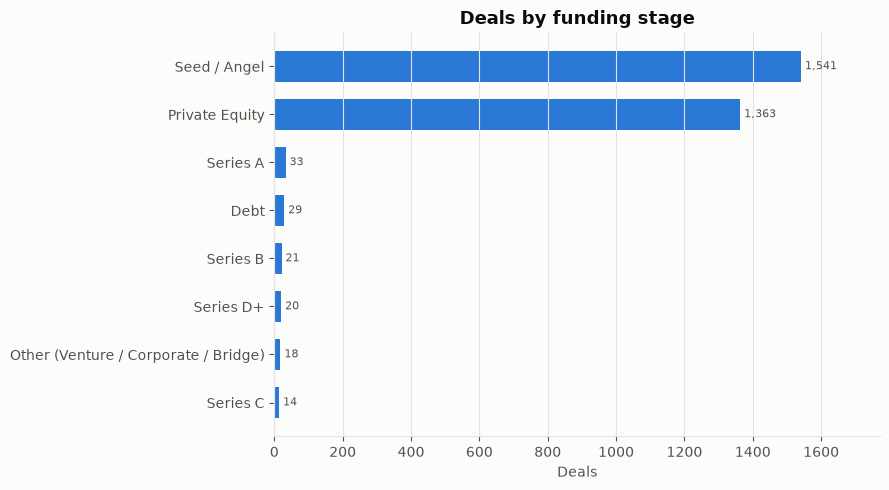

In [17]:
# Compare number of deals by funding stage
stage_deals_sorted = funding_stage_summary["deals"].sort_values()

plt.figure(figsize=(9, 5))
plt.barh(stage_deals_sorted.index, stage_deals_sorted.values, color=BLUE, height=0.65)
plt.title("Deals by funding stage")
plt.xlabel("Deals")
plt.grid(axis="y", visible=False)

for position, value in enumerate(stage_deals_sorted.values):
    plt.text(value, position, f" {value:,.0f}", va="center", fontsize=8, color=TEXT_GRAY)

plt.margins(x=0.15)
plt.tight_layout()
plt.show()

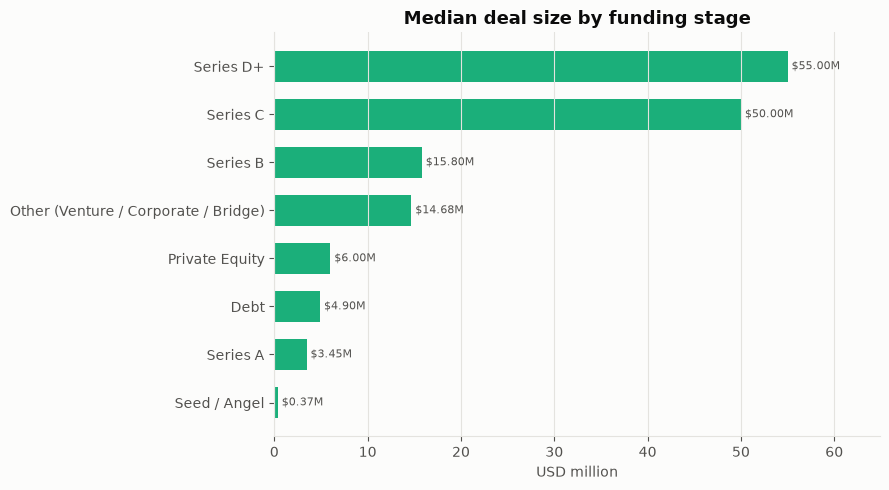

In [18]:
# Compare median deal size by funding stage
stage_median_sorted = funding_stage_summary["median_million"].dropna().sort_values()

plt.figure(figsize=(9, 5))
plt.barh(stage_median_sorted.index, stage_median_sorted.values, color=AQUA, height=0.65)
plt.title("Median deal size by funding stage")
plt.xlabel("USD million")
plt.grid(axis="y", visible=False)

for position, value in enumerate(stage_median_sorted.values):
    plt.text(value, position, f" ${value:,.2f}M", va="center", fontsize=8, color=TEXT_GRAY)

plt.margins(x=0.18)
plt.tight_layout()
plt.show()

### Top-funded startups

In [19]:
# Add up disclosed funding for each startup and show the top 15
top_funded_startups = (
    disclosed.groupby("startup_name")["amount_usd"]
    .sum()
    .div(1e6)
    .nlargest(15)
)

display(top_funded_startups.to_frame("total_disclosed_funding_usd_million").round(1))

,total_disclosed_funding_usd_million
startup_name,
Flipkart,4059.7
Paytm,3149.0
Ola Cabs,2054.2
OYO Rooms,997.0
Udaan,870.0
Flipkart.com,700.0
Snapdeal,700.0
True North,600.0
BYJU'S,525.0


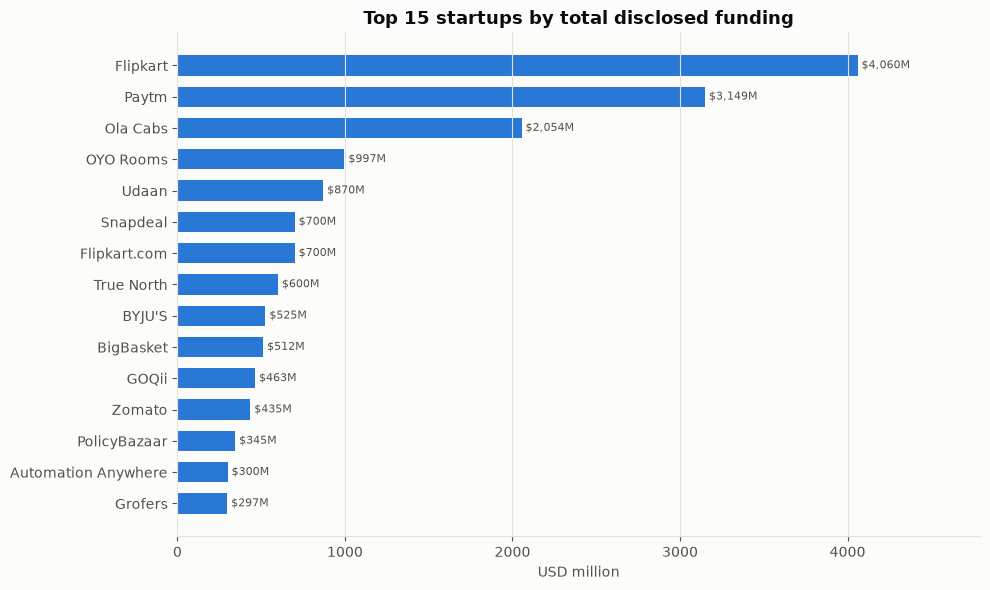

In [20]:
# Visualize the 15 startups with the highest disclosed funding
top_funded_startups_sorted = top_funded_startups.sort_values()

plt.figure(figsize=(10, 6))
plt.barh(top_funded_startups_sorted.index, top_funded_startups_sorted.values, color=BLUE, height=0.65)
plt.title("Top 15 startups by total disclosed funding")
plt.xlabel("USD million")
plt.grid(axis="y", visible=False)

for position, value in enumerate(top_funded_startups_sorted.values):
    plt.text(value, position, f" ${value:,.0f}M", va="center", fontsize=8, color=TEXT_GRAY)

plt.margins(x=0.18)
plt.tight_layout()
plt.show()

### Most active investors

In [21]:
# Remove investor entries that are marked as undisclosed
named_investors = investors[
    ~investors["investor_name"].str.contains("Undisclosed", case=False, na=False)
].copy()

# Count how many deal entries are associated with each investor
top_active_investors = named_investors["investor_name"].value_counts().head(15)

display(top_active_investors.to_frame("deals_participated"))

,deals_participated
investor_name,
Others,126
Sequoia Capital,122
Accel Partners,93
Blume Ventures,63
Kalaari Capital,60
others,60
SAIF Partners,56
Tiger Global,53
IDG Ventures,51


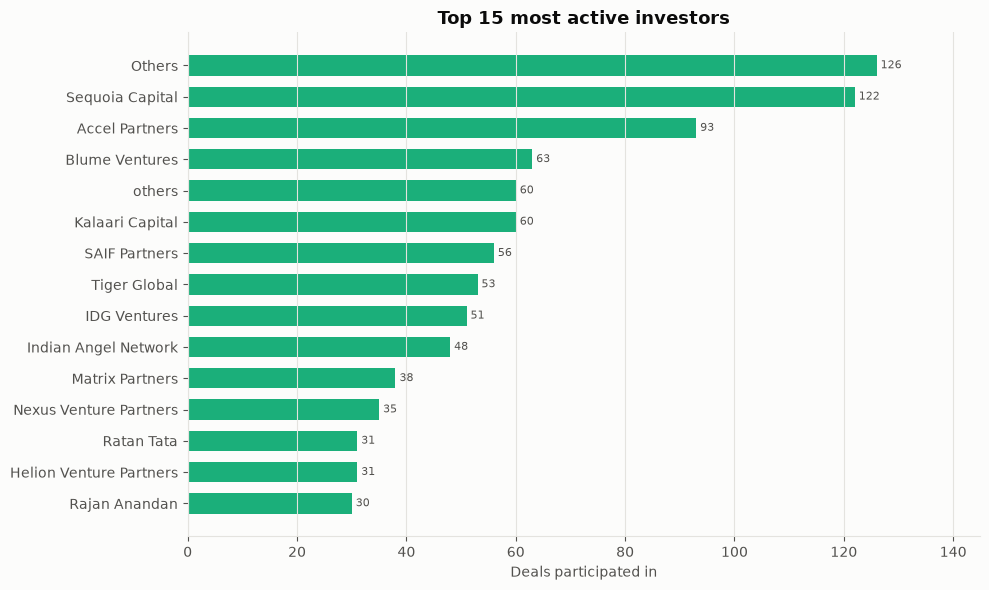

In [22]:
# Visualize the 15 most active investors
top_active_investors_sorted = top_active_investors.sort_values()

plt.figure(figsize=(10, 6))
plt.barh(top_active_investors_sorted.index, top_active_investors_sorted.values, color=AQUA, height=0.65)
plt.title("Top 15 most active investors")
plt.xlabel("Deals participated in")
plt.grid(axis="y", visible=False)

for position, value in enumerate(top_active_investors_sorted.values):
    plt.text(value, position, f" {value:,.0f}", va="center", fontsize=8, color=TEXT_GRAY)

plt.margins(x=0.15)
plt.tight_layout()
plt.show()

### Sector-by-year heatmap

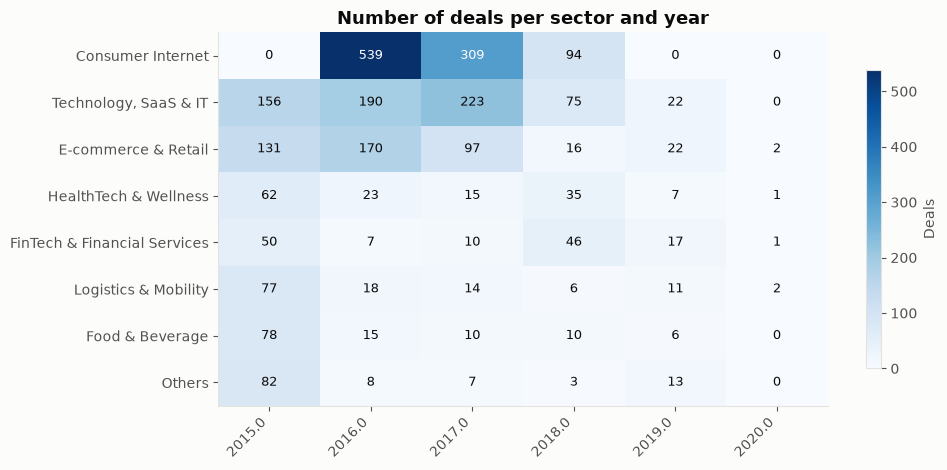

In [23]:
# Select the eight sectors with the most deals
top_sectors = sector_deals.index[:8]

# Count deals for each selected sector in each year
sector_year_heatmap = (
    known_sector[known_sector["sector"].isin(top_sectors)]
    .pivot_table(
        index="sector",
        columns="year",
        values="deal_id",
        aggfunc="count",
        fill_value=0
    )
    .reindex(top_sectors)
)

fig, ax = plt.subplots(figsize=(10, 4.8))
heatmap_image = ax.imshow(sector_year_heatmap.values, cmap="Blues", aspect="auto")
ax.set_xticks(range(len(sector_year_heatmap.columns)))
ax.set_xticklabels(sector_year_heatmap.columns.astype(str), rotation=45, ha="right")
ax.set_yticks(range(len(sector_year_heatmap.index)))
ax.set_yticklabels(sector_year_heatmap.index)
ax.grid(False)

for row_number in range(sector_year_heatmap.shape[0]):
    for column_number in range(sector_year_heatmap.shape[1]):
        cell_value = sector_year_heatmap.values[row_number, column_number]
        if cell_value > sector_year_heatmap.values.max() * 0.55:
            label_color = "white"
        else:
            label_color = INK
        ax.text(column_number, row_number, f"{cell_value}",
                ha="center", va="center", fontsize=9, color=label_color)

ax.set_title("Number of deals per sector and year")
fig.colorbar(heatmap_image, ax=ax, shrink=0.8, label="Deals")
plt.tight_layout()
plt.show()

### Funding concentration

In [24]:
# Sort disclosed deals from largest to smallest
funding_amounts_descending = np.sort(disclosed["amount_usd"].dropna().values)[::-1]
cumulative_funding_share = np.cumsum(funding_amounts_descending) / funding_amounts_descending.sum()
cumulative_deal_share = np.arange(1, len(funding_amounts_descending) + 1) / len(funding_amounts_descending)

# Calculate the share of funding going to the largest 1% and 10% of deals
top_one_percent_index = max(0, int(len(funding_amounts_descending) * 0.01) - 1)
top_ten_percent_index = max(0, int(len(funding_amounts_descending) * 0.10) - 1)
top_one_percent_share = cumulative_funding_share[top_one_percent_index]
top_ten_percent_share = cumulative_funding_share[top_ten_percent_index]

# Calculate the Gini coefficient to summarize inequality in deal sizes
funding_amounts_ascending = np.sort(disclosed["amount_usd"].dropna().values)
number_of_disclosed_deals = len(funding_amounts_ascending)
gini_coefficient = (
    2 * np.sum(np.arange(1, number_of_disclosed_deals + 1) * funding_amounts_ascending)
    / (number_of_disclosed_deals * funding_amounts_ascending.sum())
) - (number_of_disclosed_deals + 1) / number_of_disclosed_deals

print("Top 1% of deals share of disclosed funding:", f"{top_one_percent_share:.1%}")
print("Top 10% of deals share of disclosed funding:", f"{top_ten_percent_share:.1%}")
print("Gini coefficient of deal size:", f"{gini_coefficient:.3f}")

Top 1% of deals share of disclosed funding: 37.8%
Top 10% of deals share of disclosed funding: 78.2%
Gini coefficient of deal size: 0.856


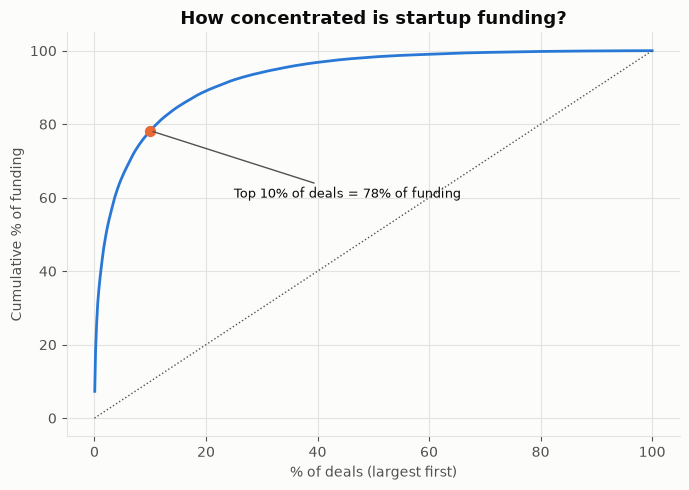

In [25]:
# Plot cumulative funding share for deals ordered from largest to smallest
plt.figure(figsize=(7, 5))
plt.plot(cumulative_deal_share * 100, cumulative_funding_share * 100, color=BLUE, linewidth=2)
plt.plot([0, 100], [0, 100], color=TEXT_GRAY, linewidth=1, linestyle=":")
plt.scatter([10], [top_ten_percent_share * 100], color=ORANGE, s=50, zorder=3)
plt.annotate(
    f"Top 10% of deals = {top_ten_percent_share:.0%} of funding",
    (10, top_ten_percent_share * 100),
    xytext=(25, 60),
    fontsize=9,
    color=INK,
    arrowprops={"arrowstyle": "-", "color": TEXT_GRAY}
)
plt.title("How concentrated is startup funding?")
plt.xlabel("% of deals (largest first)")
plt.ylabel("Cumulative % of funding")
plt.tight_layout()
plt.show()

### Funding disclosure

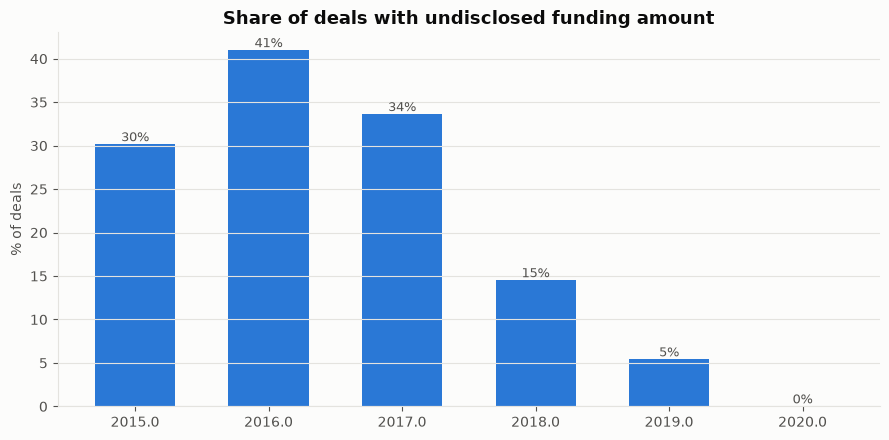

In [26]:
# Calculate the percentage of deals whose funding amounts were not disclosed
undisclosed_percentage = (1 - yearly["disclosed_rate"]) * 100

plt.figure(figsize=(9, 4.5))
plt.bar(yearly.index.astype(str), undisclosed_percentage, color=BLUE, width=0.6)
plt.title("Share of deals with undisclosed funding amount")
plt.ylabel("% of deals")
plt.grid(axis="x", visible=False)

for position, value in enumerate(undisclosed_percentage):
    plt.text(position, value, f"{value:.0f}%", ha="center", va="bottom", fontsize=9, color=TEXT_GRAY)

plt.tight_layout()
plt.show()

In [27]:
# Compare funding disclosure rates across sectors
sector_disclosure_rate = known_sector.groupby("sector")["amount_disclosed"].mean().sort_values()
sector_disclosure_percentage = sector_disclosure_rate * 100

display(sector_disclosure_percentage.to_frame("disclosure_rate_percent").round(1))

,disclosure_rate_percent
sector,
Real Estate & Home Services,56.2
Consumer Internet,62.6
HealthTech & Wellness,66.4
"Technology, SaaS & IT",66.8
E-commerce & Retail,67.1
Logistics & Mobility,71.9
Media & Entertainment,72.1
EdTech,74.4
Travel & Hospitality,75.0


### Repeat funding analysis

In [28]:
# Count the number of recorded funding deals for each startup
funding_rounds_by_startup = df.groupby("startup_name")["deal_id"].count()

startups_funded_once = (funding_rounds_by_startup == 1).mean()
startups_funded_twice_or_more = (funding_rounds_by_startup >= 2).mean()
startups_with_three_or_more_rounds = (funding_rounds_by_startup >= 3).sum()

print("Startups with one recorded deal:", f"{startups_funded_once:.1%}")
print("Startups with two or more recorded deals:", f"{startups_funded_twice_or_more:.1%}")
print("Number of startups with three or more recorded deals:", f"{startups_with_three_or_more_rounds:,}")

Startups with one recorded deal: 78.8%
Startups with two or more recorded deals: 21.2%
Number of startups with three or more recorded deals: 152


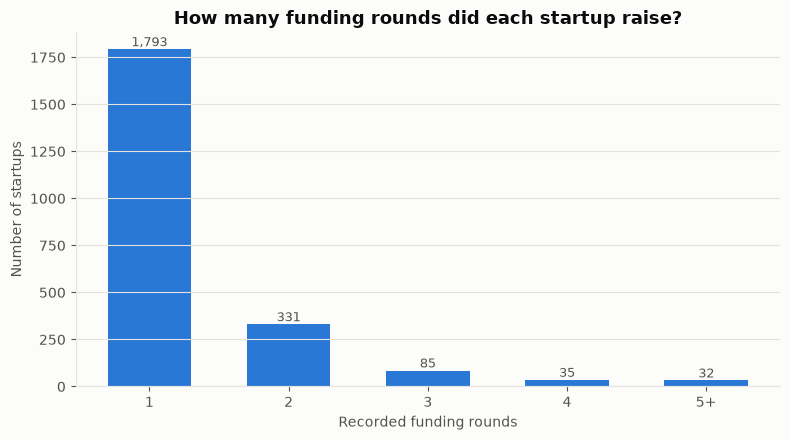

In [29]:
# Group startups by their number of funding rounds.
# Values above five are grouped together as "5+" so the chart stays readable.
round_counts = funding_rounds_by_startup.clip(upper=5).value_counts().sort_index()
round_labels = ["5+" if round_number == 5 else str(round_number) for round_number in round_counts.index]

plt.figure(figsize=(8, 4.5))
plt.bar(round_labels, round_counts.values, color=BLUE, width=0.6)
plt.title("How many funding rounds did each startup raise?")
plt.xlabel("Recorded funding rounds")
plt.ylabel("Number of startups")
plt.grid(axis="x", visible=False)

for position, value in enumerate(round_counts.values):
    plt.text(position, value, f"{value:,}", ha="center", va="bottom", fontsize=9, color=TEXT_GRAY)

plt.tight_layout()
plt.show()

### Final checks

In [30]:
print("Number of rows:", f"{len(df):,}")
print("Number of columns:", len(df.columns))
print("Duplicate deal IDs:", f"{df['deal_id'].duplicated().sum():,}")
print("Missing values by column:")
display(df.isna().sum().to_frame("missing_values"))

Number of rows: 3,043
Number of columns: 24
Duplicate deal IDs: 0
Missing values by column:


,missing_values
deal_id,0
sr_no,0
funding_date,0
year,0
quarter,0
month,0
month_name,0
year_month,0
startup_name,0
industry_vertical,170


### Notes
- Funding totals use only disclosed values where the analysis explicitly filters to disclosed deals.
- Missing or unknown sectors and cities are excluded from the relevant ranking charts.
- The analysis describes the data in the input files; it does not establish that undisclosed funding equals zero.
- Results depend on the contents and quality of the two CSV files.